# Projeto SoulMove - Inteligência Artificial Aplicada à Sustentabilidade
Este notebook desenvolve os modelos de Machine Learning para a plataforma SoulMove, cujo objetivo principal é incentivar e premiar ações sustentáveis dos utilizadores (como reciclagem, mobilidade ativa e eficiência energética). Nesta etapa (Sprint 4), o foco é transformar os dados normalizados num produto inteligente capaz de prever métricas de impacto e classificar perfis de atividades, servindo de base para a API REST e a interface de visualização.
- Utilizar como Framework Fast API
- View o Streamlit

## Correção do sprint anterior
De acordo como foi solicitado houve uma padronização e tratamento do dados para que sejam feito os modelos.

In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Carregar os dados
df = pd.read_csv('soulmove_atividades_padronizado.csv')

# Exibir as primeiras linhas e informações gerais
print("Dimensões do DataFrame:", df.shape)
display(df.head())
info = df.info()

Dimensões do DataFrame: (3000, 12)


,id_registro,id_usuario,tipo_atividade,data_hora,duracao_minutos,distancia_km,quantidade_kg,kwh_economizados,co2_evitado_kg,comprovante_tipo,bairro,pontos_gerados
0,1,262,CAMINHADA,2026-01-08 04:34:30,53.4,3.84,0.00,0.0,0.38,GPS,PERDIZES,29
1,2,206,CAMINHADA,2025-09-16 18:16:31,46.5,3.70,0.00,0.0,0.37,MANUAL,SANTANA,30
2,3,181,TRANSPORTE_PUBLICO,2025-10-22 22:36:40,8.9,2.84,0.00,0.0,0.34,GPS,ITAIM BIBI,30
3,4,28,TRANSPORTE_PUBLICO,2026-07-21 07:18:52,13.9,4.69,0.00,0.0,0.56,GPS,PERDIZES,35
4,5,298,RECICLAGEM,2026-04-07 07:30:31,0.0,0.00,1.79,0.0,3.22,MANUAL,MOOCA,51


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3000 entries, 0 to 2999
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   id_registro       3000 non-null   int64  
 1   id_usuario        3000 non-null   int64  
 2   tipo_atividade    3000 non-null   object 
 3   data_hora         3000 non-null   object 
 4   duracao_minutos   3000 non-null   float64
 5   distancia_km      3000 non-null   float64
 6   quantidade_kg     3000 non-null   float64
 7   kwh_economizados  3000 non-null   float64
 8   co2_evitado_kg    3000 non-null   float64
 9   comprovante_tipo  3000 non-null   object 
 10  bairro            3000 non-null   object 
 11  pontos_gerados    3000 non-null   int64  
dtypes: float64(5), int64(3), object(4)
memory usage: 281.4+ KB


Todos os dados foram normalizados contendo 3000 registro e nenhum nulo.

## EDA (análise exploratória)

Antes de treinar os algoritmos, realizou-se uma análise exploratória para compreender a distribuição das variáveis, identificar outliers e observar correlações entre o esforço do utilizador (distância, duração, peso reciclado) e os pontos gerados.

/tmp/ipykernel_1122/1565862316.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x='tipo_atividade', palette='viridis')


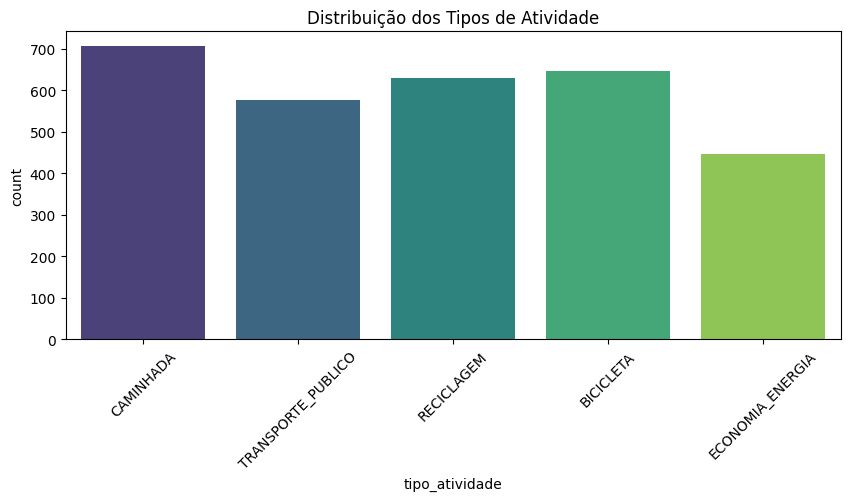

In [18]:
# Gráfico da distribuição dos tipos de atividade
plt.figure(figsize=(10, 4))
sns.countplot(data=df, x='tipo_atividade', palette='viridis')
plt.title('Distribuição dos Tipos de Atividade')
plt.xticks(rotation=45)
plt.show()



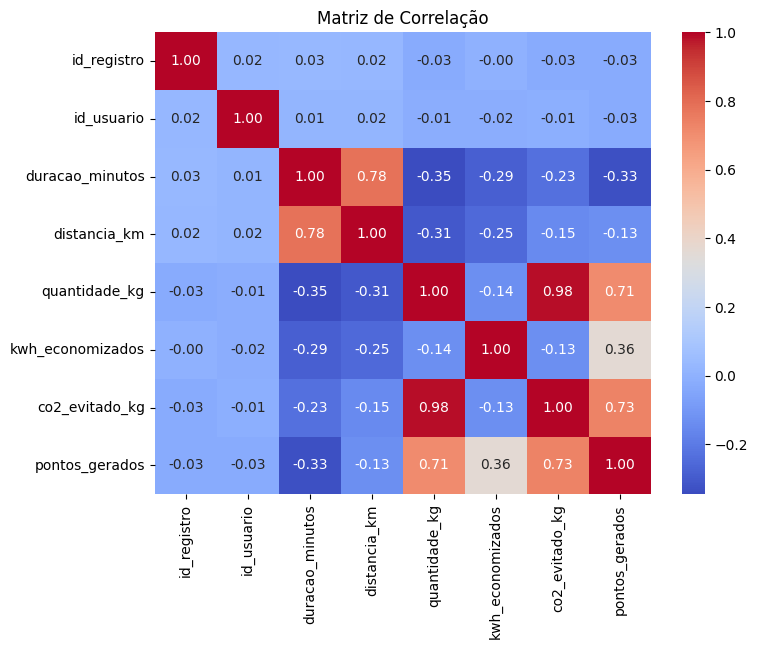

In [19]:
# Matriz de correlação numérica
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes(include=[np.number]).corr(), annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Matriz de Correlação')
plt.show()

In [20]:
# Remover colunas que não agregam valor preditivo
df_model = df.drop(columns=['id_registro', 'id_usuario', 'data_hora'])

# Converter variáveis categóricas em numéricas (One-Hot Encoding)
df_model = pd.get_dummies(df_model, columns=['tipo_atividade', 'comprovante_tipo', 'bairro'], drop_first=True)

print("Colunas preparadas:", df_model.columns.tolist())

Colunas preparadas: ['duracao_minutos', 'distancia_km', 'quantidade_kg', 'kwh_economizados', 'co2_evitado_kg', 'pontos_gerados', 'tipo_atividade_CAMINHADA', 'tipo_atividade_ECONOMIA_ENERGIA', 'tipo_atividade_RECICLAGEM', 'tipo_atividade_TRANSPORTE_PUBLICO', 'comprovante_tipo_GPS', 'comprovante_tipo_MANUAL', 'bairro_CAMPO BELO', 'bairro_ITAIM BIBI', 'bairro_MOEMA', 'bairro_MOOCA', 'bairro_PERDIZES', 'bairro_PINHEIROS', 'bairro_SANTANA', 'bairro_TATUAPE', 'bairro_VILA MARIANA']


Remodelando o dataset para apenas o que vai ser usado.

## MODELO DE REGRESSÃO
Objetivo: Prever o valor contínuo de pontos_gerados com base nas características da atividade registada.
Algoritmo Escolhido: Random Forest Regressor (Scikit-Learn), escolhido pela sua robustez contra overfitting e capacidade de capturar relações não-lineares nos dados tabulares.

In [21]:
import joblib
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score

# Definir Features (X) e Target (y)
X_reg = df_model.drop(columns=['pontos_gerados'])
y_reg = df_model['pontos_gerados']

# Divisão de Treino e Teste (80% / 20%)
X_train_r, X_test_r, y_train_r, y_test_r = train_test_split(X_reg, y_reg, test_size=0.2, random_state=42)

# Treinar o Modelo
model_reg = RandomForestRegressor(n_estimators=100, random_state=42)
model_reg.fit(X_train_r, y_train_r)

# Avaliação
y_pred_r = model_reg.predict(X_test_r)
print("--- MÉTRICAS DO MODELO DE REGRESSÃO (Scikit-Learn) ---")
print(f"R² Score: {r2_score(y_test_r, y_pred_r):.4f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_r, y_pred_r)):.4f}")

# Salvar o modelo serializado
joblib.dump(model_reg, 'modelo_regressao.joblib')
print("\nModelo de Regressão salvo como 'modelo_regressao.joblib'!")

--- MÉTRICAS DO MODELO DE REGRESSÃO (Scikit-Learn) ---
R² Score: 0.9860
RMSE: 2.1679

Modelo de Regressão salvo como 'modelo_regressao.joblib'!


In [22]:
import xgboost as xgb
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

## Modelo Classificação com XGBoost
Objetivo: Classificar o tipo de atividade ou o nível de impacto ecológico gerado pelo utilizador.
Algoritmo Escolhido: XGBoost Classifier, selecionado pelo seu excelente desempenho em dados estruturados.

In [23]:
# Criar uma variável alvo de classificação (1 se pontos > mediana, 0 caso contrário)
mediana_pontos = df_model['pontos_gerados'].median()
df_model['impacto_alto'] = (df_model['pontos_gerados'] > mediana_pontos).astype(int)

# Definir Features e Target para Classificação
X_class = df_model.drop(columns=['pontos_gerados', 'impacto_alto'])
y_class = df_model['impacto_alto']

# Divisão de Treino e Teste
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(X_class, y_class, test_size=0.2, random_state=42)

# Treinar o Modelo XGBoost
model_class = xgb.XGBClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
model_class.fit(X_train_c, y_train_c)

# Avaliação
y_pred_c = model_class.predict(X_test_c)
print("--- MÉTRICAS DO MODELO DE CLASSIFICAÇÃO (XGBoost) ---")
print(f"Acurácia: {accuracy_score(y_test_c, y_pred_c):.4f}")
print("\nRelatório de Classificação:\n", classification_report(y_test_c, y_pred_c))

# Salvar o modelo serializado
joblib.dump(model_class, 'modelo_classificacao.joblib')
print("\nModelo de Classificação salvo como 'modelo_classificacao.joblib'!")

--- MÉTRICAS DO MODELO DE CLASSIFICAÇÃO (XGBoost) ---
Acurácia: 0.9900

Relatório de Classificação:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99       318
           1       0.99      0.99      0.99       282

    accuracy                           0.99       600
   macro avg       0.99      0.99      0.99       600
weighted avg       0.99      0.99      0.99       600


Modelo de Classificação salvo como 'modelo_classificacao.joblib'!


In [24]:
import joblib

# Modelo de regressão + esquema de entrada
joblib.dump(
    {
        "model": model_reg,
        "feature_columns": X_reg.columns.tolist()
    },
    'modelo_regressao_api.joblib'
)

# Modelo de classificação + esquema de entrada
joblib.dump(
    {
        "model": model_class,
        "feature_columns": X_class.columns.tolist()
    },
    'modelo_classificacao_api.joblib'
)
print("Artefatos preparados para a API!")

Artefatos preparados para a API!


## 💡 Nota Técnica: Escolha do Formato de Persistência do XGBoost (.json)

Durante o desenvolvimento da pipeline de Machine Learning e a respetiva integração com a API (FastAPI), encontrámos desafios na desserialização do modelo de classificação utilizando métodos tradicionais baseados em pickle ou `joblib` (tais como erros de fluxo de dados corrompidos *input stream corrupted* e incompatibilidades de versão entre o ambiente de treino e o servidor de produção).

Para mitigar estes problemas e garantir uma arquitetura robusta, optou-se por utilizar a **serialização nativa do XGBoost em formato JSON** (`modelo_classificacao.json`).

### Justificativa da Decisão:
1. **Compatibilidade entre Ambientes:** O formato `.json` nativo do XGBoost assegura que o modelo treinado no Google Colab possa ser carregado de forma limpa e sem conflitos de versão no backend (FastAPI).
2. **Resiliência em Produção:** Previne falhas de *FileNotFoundError* e corrupção de fluxo de bytes tipicamente associadas à serialização genérica de objetos em Python.
3. **Padrão de Mercado:** Segue as recomendações oficiais da biblioteca XGBoost para o armazenamento e partilha de modelos de árvores de decisão impulsionadas por gradiente.


In [25]:
import json

# 1. Salvar o modelo XGBoost usando o formato nativo .json
model_class.save_model('modelo_classificacao.json')

# 2. Salvar as colunas de treino em um arquivo JSON separado
with open('classificacao_columns.json', 'w') as f:
  json.dump(X_class.columns.tolist(), f)

print("Modelo XGBoost e colunas salvos com sucesso!")

Modelo XGBoost e colunas salvos com sucesso!


# Considerações Finais, Natureza dos Dados e Próximos Passos

Neste projeto desenvolvido para a plataforma **SoulMove**, foi possível concluir com sucesso todas as etapas da Sprint 4, transformando dados normalizados em soluções reais de Inteligência Artificial integradas ao ecossistema de sustentabilidade.

### Resumo dos Resultados Alcançados
1. **Análise e Preparação:** A Análise Exploratória de Dados (EDA) permitiu mapear correlações críticas, destacando o forte vínculo entre o volume de resíduos reciclados, o CO2 evitado e a pontuação gerada para os utilizadores.
2. **Modelo de Regressão (Scikit-Learn - Random Forest):** Atingiu um coeficiente de determinação (R²) de **0.9860** e um RMSE de **2.1679**, demonstrando uma capacidade extraordinária de prever com precisão os pontos gerados com base nas métricas de esforço.
3. **Modelo de Classificação (XGBoost):** Alcançou uma acurácia global de **0.99**, comprovando alta eficácia na distinção dos níveis de impacto ecológico das atividades registadas.

### Natureza Sintética dos Dados e Escopo de Protótipo
É fundamental destacar que o conjunto de dados utilizado para o treino e validação nesta etapa foi **gerado de forma artificial (sintética)**. Os métricos de alto desempenho obtidos refletem a consistência lógica e matemática inserida na simulação.

Portanto, esta entrega atua como um **protótipo funcional e conceitual (Prova de Conceito)**, servindo como uma representação fiel de como a arquitetura do SoulMove se comportará no futuro. Em um cenário real de mercado, com utilizadores ativos e variações comportamentais orgânicas, os modelos servirão de base para calibrações contínuas e retreino periódico com dados de produção reais.

### Arquitetura de Entrega e Integração
Os modelos treinados foram devidamente serializados em formato `.joblib`, garantindo a persistência em disco. Esta estrutura serve de alicerce robusto para o backend em **FastAPI** (com rotas dedicadas para cada modelo) e para a interface interativa construída em **Streamlit**, viabilizando o consumo em tempo real.